In [1]:
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
%matplotlib inline 
np.set_printoptions(precision=4, suppress=True)


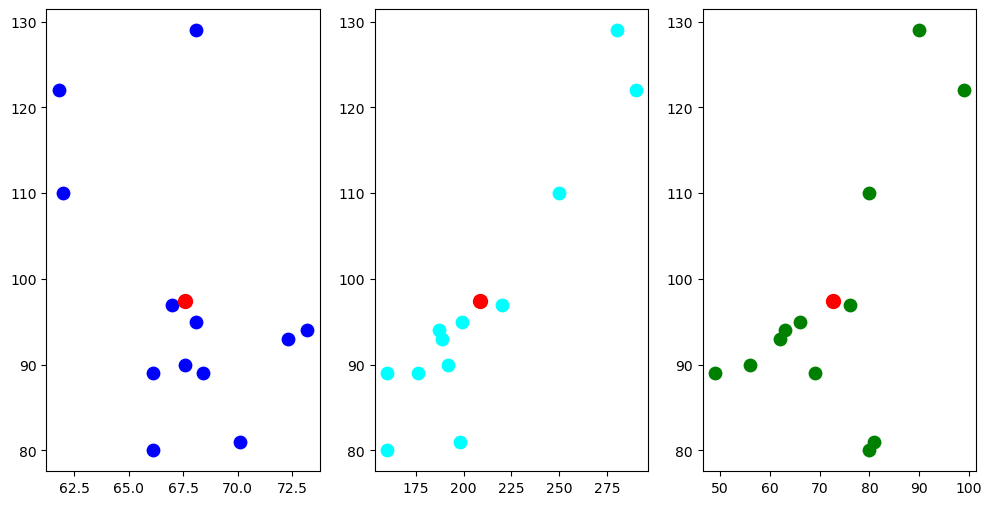

In [2]:
mean_BP = np.array([93,  94,  95,  90,  89,  110, 122, 97,  80,  81,   89,  129])
height  = np.array([72.3,73.2,68.1,67.6,66.1,62.0,61.8,67.0,66.1,70.1, 68.4, 68.1 ])
weight  = np.array([189, 187, 199, 192, 176, 250, 290, 220, 160, 198,  160, 280])
HR      = np.array([62,  63,  66,  56,  69,  80,   99, 76,  80,  81,   49,  90])

X = np.stack((height,weight,HR)).T
y = np.array(mean_BP)
ave_x = np.average(X,axis=0)
ave_y = np.average(y)
#plot data and mean
plt.figure(figsize=(12,6))
plt.subplot(1,3,1)
plt.scatter(X[:,0],y, s=80, c="blue")
plt.scatter(ave_x[0],ave_y, s=100, c="red")

plt.subplot(1,3,2)
plt.scatter(X[:,1],y, s=80, c="cyan")
plt.scatter(ave_x[1],ave_y, s=100, c="red")

plt.subplot(1,3,3)
plt.scatter(X[:,2],y, s=80, c="green")
plt.scatter(ave_x[2],ave_y, s=100, c="red")

plt.show()


In [3]:
# Now, calculate the coefficients by linear algebra
Xones = np.ones(shape=(len(X[:,0])))
Xaug = np.c_[Xones[:],X]
print(Xaug)


[[  1.   72.3 189.   62. ]
 [  1.   73.2 187.   63. ]
 [  1.   68.1 199.   66. ]
 [  1.   67.6 192.   56. ]
 [  1.   66.1 176.   69. ]
 [  1.   62.  250.   80. ]
 [  1.   61.8 290.   99. ]
 [  1.   67.  220.   76. ]
 [  1.   66.1 160.   80. ]
 [  1.   70.1 198.   81. ]
 [  1.   68.4 160.   49. ]
 [  1.   68.1 280.   90. ]]


In [4]:
XTXinv = np.linalg.inv(Xaug.T@Xaug)
theta = np.matmul(XTXinv,(Xaug.T@y))
print(theta)

[32.1684  0.0318  0.4031 -0.2882]


In [5]:
X2 = np.stack((height,weight,HR,height+weight)).T
# Now, calculate the coefficients by linear algebra
X2ones = np.ones(shape=(len(X2[:,0])))
X2aug = np.c_[X2ones[:],X2]
print(X2aug)


[[  1.   72.3 189.   62.  261.3]
 [  1.   73.2 187.   63.  260.2]
 [  1.   68.1 199.   66.  267.1]
 [  1.   67.6 192.   56.  259.6]
 [  1.   66.1 176.   69.  242.1]
 [  1.   62.  250.   80.  312. ]
 [  1.   61.8 290.   99.  351.8]
 [  1.   67.  220.   76.  287. ]
 [  1.   66.1 160.   80.  226.1]
 [  1.   70.1 198.   81.  268.1]
 [  1.   68.4 160.   49.  228.4]
 [  1.   68.1 280.   90.  348.1]]


In [7]:
XTXinv2 = np.linalg.inv(X2aug.T@X2aug)
theta2 = np.matmul(XTXinv2,(X2aug.T@y))
print(theta)
print(theta2)

[32.1684  0.0318  0.4031 -0.2882]
[483.9571  -6.25    -0.25    -0.2882   0.5   ]
